# SPHEREx × DESI real-space cross-correlation, batched by partition

Port of `2026-08-05.ipynb`. Changes:

- **Sampling**: no-replacement subsampling; `N_R = RAND_PER_DATA * N_D` randoms instead of `N_R = N_D`.
- **DESI weights**: every per-object sum is weighted by the catalog `WEIGHT` column (data and randoms).
- **Estimators**: per-object binned sums are kept, so both the note's estimator (now with the
  `1/W_D`, `1/W_R` normalizations) and the difference-of-means estimator come from the same run,
  with bootstrap errors over objects. `sum_I2` is gone.
- **Gaia**: fetched once up front, in two tiers: all-sky `G < GAIA_G_BRIGHT` (large masks), plus one
  TAP upload-join cone search around every object for fainter stars. Both are cached to disk. Masks are
  exact circles, applied in numpy (the old per-star `NOT BETWEEN` SQL chains are gone).
- **Batching by partition**: every object is assigned to the talltable partitions its disc touches;
  each partition parquet is read **once**, for all objects (data + randoms) that touch it, and pixels are
  assigned to objects with a KD-tree. An object whose disc straddles partitions accumulates contributions
  from each; every pixel lives in exactly one partition, so nothing is double counted.
- **Stack radius** is fixed in comoving units (`R_MAX_CMPC`); the angular radius is set per object.
- DuckDB's Jupyter progress bar is disabled (that was the `FloatProgress` / IOPub spam in the old notebook).

In [1]:
%env TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable

import hashlib
import itertools
import threading
import time
import warnings
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import duckdb
import healpy as hp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import pyvo
from astropy import constants as const
from astropy import units as u
from astropy.cosmology import Planck18
from astropy.io import fits
from astropy.table import Table, unique, vstack
from pyvo.dal.exceptions import DALServiceError
from scipy.spatial import cKDTree
from tqdm.auto import tqdm

from talltable.constants import HP_HIGH_LEVEL
from talltable.partition import find_partitions_disc, part_to_level_index
from talltable.paths import PART_DB_PATH, PIXEL_DB_PATH, WAVES_DB_PATH
from talltable.query import indices_to_hphigh_ranges

env: TALLTABLE_DB_DIR=/mnt/sdceph/users/spherex/talltable


## configuration

In [2]:
Z_MIN, Z_MAX = 1.0, 1.01
N_DATA = 2000             # data sample size; None -> every galaxy in the z-bin
RAND_PER_DATA = 10        # N_R = RAND_PER_DATA * N_D

DATA_PATH  = '../data/ELG_LOPnotqso_NGC_clustering.dat.fits'
RAND_PATHS = ['../data/ELG_LOPnotqso_NGC_0_clustering.ran.fits']   # add _1_, _2_, ... for more randoms

WL_REST_HALPHA = 0.656    # µm
N_WL_BINS = 11
RESOLUTION = 120

R_MAX_CMPC = 0.8          # comoving transverse radius of the stack [Mpc]
N_R_BINS = 31

GAIA_G_MAX = 20.0         # mask Gaia stars brighter than this
GAIA_G_BRIGHT = 9.0       # stars brighter than this are fetched all-sky (their masks are large)
GAIA_CACHE_DIR = Path('../data/gaia_cache')

ALLOWED_FLAGS = 1 << 21   # allow bit 21 (SOURCE), reject every other flag
RANGE_LEVEL = 14          # HEALPix level of the hphigh ranges used to select row groups and rows

N_WORKERS = 16            # partitions processed concurrently (reads are latency-bound on ceph)

OUT_PATH = Path('../data/stack_2026-09-24.npz')

RNG = np.random.default_rng(110)

## load catalogs

In [3]:
def load_catalog(paths, n=None):
    cols = defaultdict(list)
    for path in paths:
        with fits.open(path, memmap=True) as hdul:
            x = hdul[1].data
            m = (x['Z'] > Z_MIN) & (x['Z'] < Z_MAX)
            print(f"  {Path(path).name}: {len(x)} rows, {m.sum()} after z cuts")
            cols['ra'].append(np.array(x['RA'][m], dtype=np.float64))
            cols['dec'].append(np.array(x['DEC'][m], dtype=np.float64))
            cols['z'].append(np.array(x['Z'][m], dtype=np.float64))
            if 'WEIGHT' in x.columns.names:
                cols['w'].append(np.array(x['WEIGHT'][m], dtype=np.float64))
            else:
                print(f"  WARNING: no WEIGHT column in {path}; using unit weights")
                cols['w'].append(np.ones(m.sum()))
    cat = {k: np.concatenate(v) for k, v in cols.items()}

    if n is not None:
        if n > len(cat['z']):
            print(f"  WARNING: asked for {n} objects but only {len(cat['z'])} available; using all")
        else:
            idx = RNG.choice(len(cat['z']), size=n, replace=False)
            cat = {k: v[idx] for k, v in cat.items()}
            print(f"  ..subsampled to {n}")
    return cat

print("Loading data:")
data = load_catalog([DATA_PATH], N_DATA)

print("\nLoading randoms:")
rand = load_catalog(RAND_PATHS, RAND_PER_DATA * len(data['z']))

N_D, N_R = len(data['z']), len(rand['z'])
print(f"\nN_D = {N_D}, N_R = {N_R} (ratio {N_R / N_D:.1f})")
print(f"sum of weights: data {data['w'].sum():.1f}, randoms {rand['w'].sum():.1f}")

Loading data:
  ELG_LOPnotqso_NGC_clustering.dat.fits: 1821322 rows, 27803 after z cuts
  ..subsampled to 2000

Loading randoms:
  ELG_LOPnotqso_NGC_0_clustering.ran.fits: 9719822 rows, 147732 after z cuts
  ..subsampled to 20000

N_D = 2000, N_R = 20000 (ratio 10.0)
sum of weights: data 1920.7, randoms 17320.4


In [4]:
# one combined object table: data first, then randoms
objs = {k: np.concatenate([data[k], rand[k]]) for k in data}
is_rand = np.r_[np.zeros(N_D, bool), np.ones(N_R, bool)]
n_obj = len(is_rand)

obj_D_M   = Planck18.comoving_transverse_distance(objs['z']).to(u.Mpc).value
obj_theta = R_MAX_CMPC / obj_D_M                                   # stack radius [rad]
obj_vec   = hp.ang2vec(objs['ra'], objs['dec'], lonlat=True)       # (n_obj, 3) unit vectors

print(f"stack radius: {np.degrees(obj_theta).min() * 60:.3f}' - {np.degrees(obj_theta).max() * 60:.3f}'")

stack radius: 0.804' - 0.810'


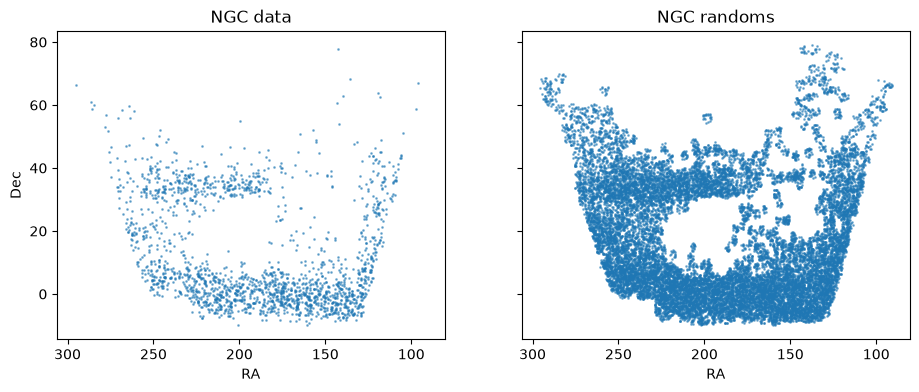

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, sel, title in [(axs[0], ~is_rand, 'data'), (axs[1], is_rand, 'randoms')]:
    ax.scatter(objs['ra'][sel], objs['dec'][sel], s=1, alpha=0.5)
    ax.set_title(f'NGC {title}')
    ax.set_xlabel('RA')
axs[0].set_ylabel('Dec')
axs[0].xaxis.set_inverted(True)
plt.show()

## choose bins

In [6]:
r_bins = np.linspace(0, R_MAX_CMPC, N_R_BINS + 1)

# narrow rest-frame band around H-alpha, log-spaced at resolution R = lambda/dlambda
half_ln_width = (N_WL_BINS / RESOLUTION) / 2
WL_REST_MIN = WL_REST_HALPHA * np.exp(-half_ln_width)
WL_REST_MAX = WL_REST_HALPHA * np.exp(+half_ln_width)
wl_bins = np.geomspace(WL_REST_MIN, WL_REST_MAX, N_WL_BINS + 1)

# fixed observed-frame query band wide enough to cover every object's redshifted window
QUERY_WL_MIN = WL_REST_MIN * (1 + objs['z'].min())
QUERY_WL_MAX = WL_REST_MAX * (1 + objs['z'].max())

n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1
n_bins = n_r * n_wl

r_c  = 0.5 * (r_bins[:-1] + r_bins[1:])
wl_c = 0.5 * (wl_bins[:-1] + wl_bins[1:])

## Gaia star mask

Two tiers, both fetched once from IRSA TAP and cached under `GAIA_CACHE_DIR`:

- **bright** (`G < GAIA_G_BRIGHT`): all-sky, ~180k stars, ~35 s. These have masks up to degrees, so
  they must be found far from the objects.
- **faint** (`GAIA_G_BRIGHT <= G < GAIA_G_MAX`): a single upload-join cone search around every object
  (chunked), with radius = largest stack radius + mask radius at `GAIA_G_BRIGHT`. About 10 s per 2000
  objects.

The faint-tier cache file is keyed by a hash of the object positions and query radius, so changing the
sample triggers a re-fetch. To force one, delete the cache files.

In [7]:
IRSA_TAP = pyvo.dal.TAPService('https://irsa.ipac.caltech.edu/TAP')

def crude_mask_radius(m):
    # arcsec
    return 8.0 + 4e3 * 10 ** (-0.25 * m)

def run_tap(query, uploads=None, max_retries=5):
    for attempt in range(max_retries):
        try:
            return IRSA_TAP.run_async(query, uploads=uploads, maxrec=50_000_000).to_table()
        except DALServiceError:
            if attempt == max_retries - 1:
                raise
            time.sleep(2 ** attempt + np.random.uniform(0, 1))

def fetch_gaia_bright():
    cache = GAIA_CACHE_DIR / f'gaia_dr3_G_lt_{GAIA_G_BRIGHT:g}.fits'
    if cache.exists():
        return Table.read(cache)
    t = run_tap(f'''
SELECT source_id, ra, dec, phot_g_mean_mag
FROM gaia_dr3_source
WHERE phot_g_mean_mag < {GAIA_G_BRIGHT}
''')
    cache.parent.mkdir(parents=True, exist_ok=True)
    t.write(cache)
    return t

def fetch_gaia_near(ra, dec, radius_deg, chunk=5000):
    key = hashlib.sha1(
        np.round(ra, 6).tobytes() + np.round(dec, 6).tobytes()
        + f'{radius_deg:.6f},{GAIA_G_BRIGHT},{GAIA_G_MAX}'.encode()
    ).hexdigest()[:12]
    cache = GAIA_CACHE_DIR / f'gaia_dr3_near_{key}.fits'
    if cache.exists():
        return Table.read(cache)

    query = f'''
SELECT g.source_id, g.ra, g.dec, g.phot_g_mean_mag
FROM gaia_dr3_source AS g, TAP_UPLOAD.objs AS o
WHERE 1 = CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', o.ra, o.dec, {radius_deg}))
AND g.phot_g_mean_mag >= {GAIA_G_BRIGHT}
AND g.phot_g_mean_mag < {GAIA_G_MAX}
'''
    tables = []
    for i in tqdm(range(0, len(ra), chunk), desc='gaia (faint)'):
        upload = Table({'ra': ra[i:i + chunk], 'dec': dec[i:i + chunk]})
        tables.append(run_tap(query, uploads={'objs': upload}))
    t = unique(vstack(tables), keys='source_id')   # neighboring cones overlap

    cache.parent.mkdir(parents=True, exist_ok=True)
    t.write(cache)
    return t

In [8]:
def make_star_set(t):
    g = np.ma.filled(np.asarray(t['phot_g_mean_mag'], dtype=np.float64), np.nan)
    ok = np.isfinite(g)
    ra, dec = np.asarray(t['ra'], np.float64)[ok], np.asarray(t['dec'], np.float64)[ok]
    vec = hp.ang2vec(ra, dec, lonlat=True).reshape(-1, 3)
    r_mask = np.radians(crude_mask_radius(g[ok]) / 3600)
    return {
        'vec': vec,
        'r_mask': r_mask,
        'r_max': r_mask.max() if len(r_mask) else 0.0,
        'tree': cKDTree(vec),
    }

t0 = time.time()
gaia_bright = fetch_gaia_bright()
faint_radius_deg = np.degrees(obj_theta.max()) + crude_mask_radius(GAIA_G_BRIGHT) / 3600
gaia_faint = fetch_gaia_near(objs['ra'], objs['dec'], faint_radius_deg)
print(f"Gaia: {len(gaia_bright)} bright + {len(gaia_faint)} faint stars ({time.time() - t0:.0f} s)")

star_sets = [make_star_set(gaia_bright), make_star_set(gaia_faint)]

Gaia: 177426 bright + 129753 faint stars (0 s)


## assign objects to partitions

Each talltable partition is a nested-HEALPix cell (levels 6-10, adaptive) and every sky pixel belongs to
exactly one partition. Build the inverse map partition → [objects whose disc touches it].

In [9]:
with open(PART_DB_PATH) as f:
    ALL_PARTS = {int(line) for line in f if line.strip()}

part_objs = defaultdict(list)
for k in tqdm(range(n_obj), desc='partitions'):
    for p in find_partitions_disc(objs['ra'][k], objs['dec'][k], np.degrees(obj_theta[k]), all_parts=ALL_PARTS):
        part_objs[int(p)].append(k)
part_objs = {p: np.array(ks) for p, ks in part_objs.items()}

n_per_part = np.array([len(ks) for ks in part_objs.values()])
n_pairs = n_per_part.sum()
print(f"{len(part_objs)} partitions for {n_obj} objects")
print(f"objects per partition: median {np.median(n_per_part):.0f}, max {n_per_part.max()}")
print(f"(object, partition) pairs: {n_pairs} ({n_pairs / n_obj:.2f} partitions per object)")

partitions:   0%|          | 0/22000 [00:00<?, ?it/s]

7029 partitions for 22000 objects
objects per partition: median 3, max 17
(object, partition) pairs: 24103 (1.10 partitions per object)


## query & stack

For each partition, `process_partition`:

1. builds `hphigh` ranges (level `RANGE_LEVEL`) covering the union of its objects' discs, clipped to the partition;
2. reads the parquet footer, keeps only the **row groups** whose `hphigh` min/max overlaps a range, and reads just
   those (with `pre_buffer=True`, so each row group's column chunks come in as a few large coalesced reads rather
   than scattered small ones);
3. filters rows in numpy: inside a range, allowed flags, `waveid` in the observed-frame window;
4. marks pixels inside any Gaia mask (KD-tree over the partition's unique sky pixels);
5. assigns pixels to each object with the same KD-tree, bins in `(r, λ_rest)` and returns per-object
   sums `S = Σ I_rest` and counts `C = Σ 1`.

This replaced a single DuckDB query per partition: DuckDB only used the overall `hphigh` min/max for row-group
pruning, not the OR of ranges, so for objects spread across a partition it scanned most of the file (tens of millions
of rows) and evaluated hundreds of `BETWEEN`s per row.

The main thread adds the per-object results into `S_all`, `C_all` with shape `(n_obj, n_r * n_wl)`.

In [10]:
# waves in the observed-frame window, loaded once, sorted by waveid for lookups
_waves = duckdb.sql(f'''
SELECT waveid, wavelength
FROM read_parquet('{WAVES_DB_PATH}')
WHERE wavelength BETWEEN {QUERY_WL_MIN} AND {QUERY_WL_MAX}
ORDER BY waveid
''').fetchnumpy()
WAVE_IDS = np.asarray(_waves['waveid'])
WAVE_WL  = np.asarray(_waves['wavelength'])
print(f"{len(WAVE_IDS)} waveids in {QUERY_WL_MIN:.4f} - {QUERY_WL_MAX:.4f} µm")

C_UM_HZ = const.c.to(u.um / u.s).value   # nu [Hz] = C_UM_HZ / lambda [µm]
PIXEL_COLUMNS = ['hphigh', 'waveid', 'flux', 'zodi', 'flags']

def chord(angle):
    # KD-trees work in 3D Euclidean distance between unit vectors
    return 2 * np.sin(0.5 * np.asarray(angle))

def flatten_idx(lists):
    return np.fromiter(itertools.chain.from_iterable(lists), dtype=np.intp)

def partition_path(part):
    return PIXEL_DB_PATH / f'part={part}' / 'compacted.parquet'

def partition_span(part):
    level, index = part_to_level_index(int(part))
    shift = 2 * (HP_HIGH_LEVEL - level)
    return index << shift, ((index + 1) << shift) - 1

def disc_ranges(vecs, radii, span, level=RANGE_LEVEL):
    # sorted, merged, inclusive hphigh ranges covering the union of discs, clipped to the partition span
    lo_p, hi_p = span
    ipix = np.concatenate([
        hp.query_disc(2**level, v, r, nest=True, inclusive=True)
        for v, r in zip(vecs, radii)
    ])
    ranges = np.array(indices_to_hphigh_ranges(ipix, level), dtype=np.int64).reshape(-1, 2)
    ranges[:, 0] = np.maximum(ranges[:, 0], lo_p)
    ranges[:, 1] = np.minimum(ranges[:, 1], hi_p)
    return ranges[ranges[:, 0] <= ranges[:, 1]]

def last_range_starting_at_or_before(x, ranges):
    # ranges are sorted and non-overlapping, so this range also has the largest `hi` among those starting <= x
    return np.searchsorted(ranges[:, 0], x, side='right') - 1

def select_row_groups(pf, ranges):
    md = pf.metadata
    j = pf.schema_arrow.get_field_index('hphigh')
    lo = np.full(md.num_row_groups, np.iinfo(np.int64).min)
    hi = np.full(md.num_row_groups, np.iinfo(np.int64).max)
    for g in range(md.num_row_groups):
        st = md.row_group(g).column(j).statistics
        if st is not None and st.has_min_max:
            lo[g], hi[g] = st.min, st.max
    # row group [lo, hi] overlaps a range iff the last range starting <= hi ends >= lo
    i = last_range_starting_at_or_before(hi, ranges)
    return np.flatnonzero((i >= 0) & (ranges[np.maximum(i, 0), 1] >= lo))

def read_partition(part, ranges):
    # returns (hphigh, wavelength, flux, zodi) for good pixels inside `ranges`, or None
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges)
    if len(rgs) == 0:
        return None
    t = pf.read_row_groups(rgs, columns=PIXEL_COLUMNS)

    h = t.column('hphigh').to_numpy()
    i = last_range_starting_at_or_before(h, ranges)
    keep = (i >= 0) & (h <= ranges[np.maximum(i, 0), 1])
    keep &= (t.column('flags').to_numpy().astype(np.int64) & ~ALLOWED_FLAGS) == 0
    idx = np.flatnonzero(keep)

    waveid = t.column('waveid').to_numpy()[idx]
    pos = np.minimum(np.searchsorted(WAVE_IDS, waveid), len(WAVE_IDS) - 1)
    in_window = WAVE_IDS[pos] == waveid
    idx, pos = idx[in_window], pos[in_window]
    return (
        h[idx],
        WAVE_WL[pos],
        t.column('flux').to_numpy()[idx],
        t.column('zodi').to_numpy()[idx],
    )

def star_mask(pix_tree, n_pix, ks):
    masked = np.zeros(n_pix, dtype=bool)
    for st in star_sets:
        if len(st['r_mask']) == 0:
            continue
        # stars that could reach any of these objects' discs
        cand = np.unique(flatten_idx(
            st['tree'].query_ball_point(obj_vec[ks], chord(obj_theta[ks] + st['r_max']))
        ))
        if cand.size == 0:
            continue
        hits = flatten_idx(pix_tree.query_ball_point(st['vec'][cand], chord(st['r_mask'][cand])))
        masked[hits] = True
    return masked

def process_partition(part, ks):
    S = np.zeros((len(ks), n_bins))
    C = np.zeros((len(ks), n_bins), dtype=np.int64)

    ranges = disc_ranges(obj_vec[ks], obj_theta[ks], partition_span(part))
    if len(ranges) == 0:
        return ks, S, C
    rows = read_partition(part, ranges)
    if rows is None or len(rows[0]) == 0:
        return ks, S, C
    hphigh, wl_obs, flux, zodi = rows
    I_obs = (C_UM_HZ / wl_obs) * (flux - zodi)   # nu I_nu

    # unique sky pixels; rows grouped by pixel (CSR layout: rows of pixel i are order[starts[i]:starts[i]+counts[i]])
    upix, inv = np.unique(hphigh, return_inverse=True)
    pix_vec = np.stack(hp.pix2vec(2**HP_HIGH_LEVEL, upix, nest=True), axis=1)
    pix_tree = cKDTree(pix_vec)
    order  = np.argsort(inv, kind='stable')
    counts = np.bincount(inv, minlength=len(upix))
    starts = np.cumsum(counts) - counts

    masked = star_mask(pix_tree, len(upix), ks)

    in_disc = pix_tree.query_ball_point(obj_vec[ks], chord(obj_theta[ks]))
    for j, k in enumerate(ks):
        sel = np.asarray(in_disc[j], dtype=np.intp)
        sel = sel[~masked[sel]]
        if sel.size == 0:
            continue

        sep = 2 * np.arcsin(0.5 * np.linalg.norm(pix_vec[sel] - obj_vec[k], axis=1))
        i_r_pix = np.digitize(sep * obj_D_M[k], r_bins) - 1

        lens = counts[sel]
        rows = order[np.repeat(starts[sel] - (np.cumsum(lens) - lens), lens) + np.arange(lens.sum())]
        i_r  = np.repeat(i_r_pix, lens)
        i_wl = np.digitize(wl_obs[rows] / (1 + objs['z'][k]), wl_bins) - 1

        ok = (i_r >= 0) & (i_r < n_r) & (i_wl >= 0) & (i_wl < n_wl)
        flat = i_r[ok] * n_wl + i_wl[ok]
        I_rest = (1 + objs['z'][k]) ** 4 * I_obs[rows[ok]]
        S[j] = np.bincount(flat, weights=I_rest, minlength=n_bins)
        C[j] = np.bincount(flat, minlength=n_bins)

    return ks, S, C

969285 waveids in 1.2532 - 1.3804 µm


Optional: time a random sample of partitions (cold reads) before launching the full loop, and extrapolate.

In [11]:
# biggest partitions first, for load balance
parts = sorted(part_objs, key=lambda p: -len(part_objs[p]))

def profile_partition(part):
    ks = part_objs[part]
    t0 = time.perf_counter()
    ranges = disc_ranges(obj_vec[ks], obj_theta[ks], partition_span(part))
    pf = pq.ParquetFile(partition_path(part), pre_buffer=True)
    rgs = select_row_groups(pf, ranges) if len(ranges) else np.array([], int)
    t_meta = time.perf_counter() - t0

    t0 = time.perf_counter()
    if len(rgs):
        pf.read_row_groups(rgs, columns=PIXEL_COLUMNS)
    t_read = time.perf_counter() - t0

    t0 = time.perf_counter()
    process_partition(part, ks)   # whole thing again, now with a warm cache
    t_warm = time.perf_counter() - t0

    md = pf.metadata
    size_gb = partition_path(part).stat().st_size / 1e9
    print(f"part {part}: {len(ks):2d} objs, {len(ranges):3d} ranges | "
          f"{len(rgs):3d} / {md.num_row_groups} row groups ({md.num_rows / md.num_row_groups / 1e6:.2f}M rows each; "
          f"file {size_gb:.2f} GB) | meta {t_meta:.2f}s, read (cold) {t_read:.2f}s, all (warm) {t_warm:.2f}s")
    return t_meta + t_read + t_warm

sample = np.random.default_rng(0).choice(len(parts), size=min(8, len(parts)), replace=False)
t_cold = np.mean([profile_partition(parts[k]) for k in sample])
print(f"\n~{t_cold:.2f} s per partition -> ~{t_cold * len(parts) / N_WORKERS / 60:.0f} min "
      f"for {len(parts)} partitions with {N_WORKERS} workers (if reads scale that far)")

part 1053045:  1 objs,  14 ranges |   2 / 72 row groups (1.05M rows each; file 1.29 GB) | meta 0.01s, read (cold) 0.61s, all (warm) 0.08s
part 1074845:  7 objs,  98 ranges |  12 / 101 row groups (1.04M rows each; file 1.82 GB) | meta 0.00s, read (cold) 0.20s, all (warm) 0.50s
part 1076096:  9 objs, 126 ranges |  14 / 70 row groups (1.04M rows each; file 1.25 GB) | meta 0.01s, read (cold) 2.63s, all (warm) 0.56s
part 1070449:  3 objs,  44 ranges |   5 / 71 row groups (1.04M rows each; file 1.28 GB) | meta 0.01s, read (cold) 1.52s, all (warm) 0.19s
part 1054879:  4 objs,  42 ranges |   8 / 61 row groups (1.04M rows each; file 1.09 GB) | meta 0.02s, read (cold) 2.07s, all (warm) 0.30s
part 1079922:  5 objs,  71 ranges |  10 / 69 row groups (1.04M rows each; file 1.24 GB) | meta 0.01s, read (cold) 2.52s, all (warm) 0.39s
part 1074966:  8 objs,  96 ranges |  14 / 99 row groups (1.05M rows each; file 1.79 GB) | meta 0.00s, read (cold) 2.66s, all (warm) 0.56s
part 1052817:  2 objs,  19 ranges

In [12]:
S_all = np.zeros((n_obj, n_bins))
C_all = np.zeros((n_obj, n_bins), dtype=np.int64)

# biggest partitions first, for load balance
parts = sorted(part_objs, key=lambda p: -len(part_objs[p]))

t0 = time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = [ex.submit(process_partition, p, part_objs[p]) for p in parts]
    try:
        for fut in tqdm(as_completed(futures), total=len(futures), desc='partitions'):
            ks, S, C = fut.result()
            S_all[ks] += S
            C_all[ks] += C
    except BaseException:
        ex.shutdown(wait=False, cancel_futures=True)
        raise
print(f"done in {time.time() - t0:.0f} s; {(C_all.sum(1) == 0).sum()} objects with no pixels")

OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    OUT_PATH, S=S_all, C=C_all, is_rand=is_rand, r_bins=r_bins, wl_bins=wl_bins,
    **{f'obj_{k}': v for k, v in objs.items()},
)

partitions:   0%|          | 0/7029 [00:00<?, ?it/s]

done in 1129 s; 7 objects with no pixels


In [13]:
# to reload a finished run instead of recomputing (after running the config cell):
# f = np.load(OUT_PATH)
# S_all, C_all, is_rand, r_bins, wl_bins = f['S'], f['C'], f['is_rand'], f['r_bins'], f['wl_bins']
# objs = {k[4:]: f[k] for k in f.files if k.startswith('obj_')}
# n_r, n_wl = len(r_bins) - 1, len(wl_bins) - 1
# r_c, wl_c = 0.5 * (r_bins[:-1] + r_bins[1:]), 0.5 * (wl_bins[:-1] + wl_bins[1:])

## estimators

With per-object sums $S_o$, counts $C_o$ and DESI weights $w_o$, and $W_X = \sum_{o \in X} w_o$:

- **difference of means**: $\hat J = \dfrac{\sum_D w S}{\sum_D w C} - \dfrac{\sum_R w S}{\sum_R w C}$
- **note's estimator** (with the normalizations added): $\hat J_{\rm note} = \dfrac{\sum_D w S / W_D - \sum_R w S / W_R}{\sum_R w C / W_R}$

They differ by $(\text{pair-count ratio} - 1) \times \langle I \rangle_D$, where the pair-count ratio is
$(\sum_D w C / W_D) / (\sum_R w C / W_R)$.

Errors: bootstrap over objects, resampling data and randoms independently. This ignores correlations
between objects that share pixels, so a jackknife over sky regions is the better next step.

In [14]:
S3 = S_all.reshape(-1, n_r, n_wl)
C3 = C_all.reshape(-1, n_r, n_wl)
w_obj = objs['w']
iD, iR = np.flatnonzero(~is_rand), np.flatnonzero(is_rand)
S3D, C3D, S3R, C3R = S3[iD], C3[iD], S3[iR], C3[iR]

def estimators(mD, mR):
    # mD, mR: per-object multiplicities (all ones for the full sample; bootstrap counts otherwise)
    wD, wR = w_obj[iD] * mD, w_obj[iR] * mR
    SD, CD = np.tensordot(wD, S3D, 1), np.tensordot(wD, C3D, 1)
    SR, CR = np.tensordot(wR, S3R, 1), np.tensordot(wR, C3R, 1)
    WD, WR = wD.sum(), wR.sum()
    with np.errstate(divide='ignore', invalid='ignore'):
        J_diff = SD / CD - SR / CR
        J_note = (SD / WD - SR / WR) / (CR / WR)
        pc_ratio = (CD / WD) / (CR / WR)
    return J_diff, J_note, pc_ratio

J_diff, J_note, pc_ratio = estimators(np.ones(len(iD)), np.ones(len(iR)))

N_BOOT = 200
boots = np.array([
    estimators(
        np.bincount(RNG.integers(0, len(iD), len(iD)), minlength=len(iD)),
        np.bincount(RNG.integers(0, len(iR), len(iR)), minlength=len(iR)),
    )
    for _ in tqdm(range(N_BOOT), desc='bootstrap')
])
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)   # bins that are empty in every resample
    J_diff_err, J_note_err, pc_ratio_err = np.nanstd(boots, axis=0)

h_alpha_index = np.argmin(np.abs(wl_c - WL_REST_HALPHA))

bootstrap:   0%|          | 0/200 [00:00<?, ?it/s]

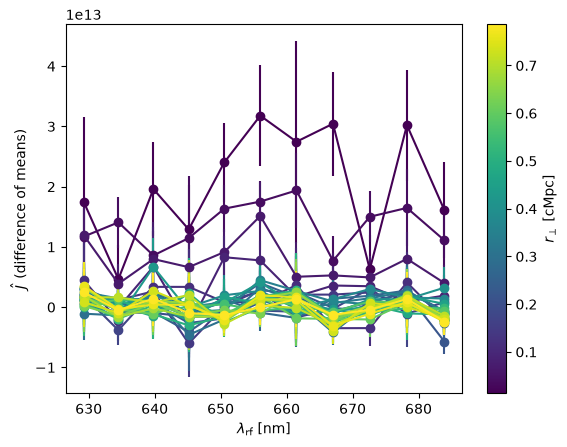

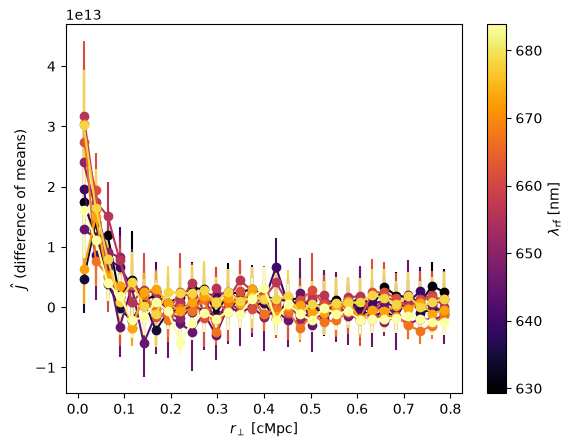

In [15]:
cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(r_c.min(), r_c.max())

fig, ax = plt.subplots()
for i in range(n_r):
    ax.errorbar(wl_c * 1e3, J_diff[i], J_diff_err[i], marker='o', color=cmap(norm(r_c[i])))
ax.set_xlabel(r'$\lambda_{\rm rf}$ [nm]')
ax.set_ylabel(r'$\hat J$ (difference of means)')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$r_\perp$ [cMpc]')
plt.show()


cmap = plt.get_cmap('inferno')
norm = mpl.colors.Normalize(wl_c.min() * 1e3, wl_c.max() * 1e3)

fig, ax = plt.subplots()
for j in range(n_wl):
    ax.errorbar(r_c, J_diff[:, j], J_diff_err[:, j], marker='o', color=cmap(norm(wl_c[j] * 1e3)))
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'$\hat J$ (difference of means)')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=ax, label=r'$\lambda_{\rm rf}$ [nm]')
plt.show()

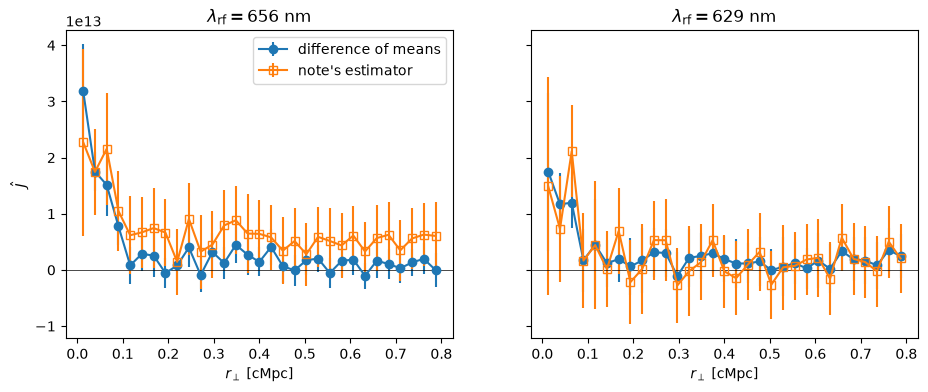

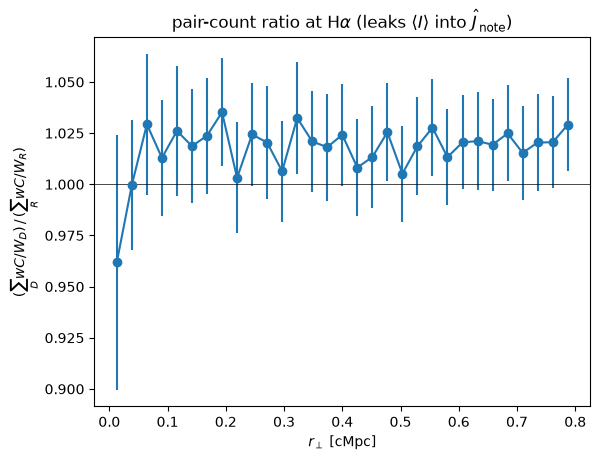

In [16]:
# the two estimators at H-alpha and at a continuum bin; they should agree where the pair-count ratio is ~1
j_cont = 0
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, j in zip(axs, [h_alpha_index, j_cont]):
    ax.errorbar(r_c, J_diff[:, j], J_diff_err[:, j], marker='o', label='difference of means')
    ax.errorbar(r_c, J_note[:, j], J_note_err[:, j], marker='s', mfc='none', label="note's estimator")
    ax.axhline(0, color='k', lw=0.5)
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_title(rf'$\lambda_{{\rm rf}} = {wl_c[j] * 1e3:.0f}$ nm')
axs[0].set_ylabel(r'$\hat J$')
axs[0].legend()
plt.show()

fig, ax = plt.subplots()
ax.errorbar(r_c, pc_ratio[:, h_alpha_index], pc_ratio_err[:, h_alpha_index], marker='o')
ax.axhline(1, color='k', lw=0.5)
ax.set_xlabel(r'$r_\perp$ [cMpc]')
ax.set_ylabel(r'$(\sum_D wC / W_D) \, / \, (\sum_R wC / W_R)$')
ax.set_title(r'pair-count ratio at H$\alpha$ (leaks $\langle I \rangle$ into $\hat J_{\rm note}$)')
plt.show()

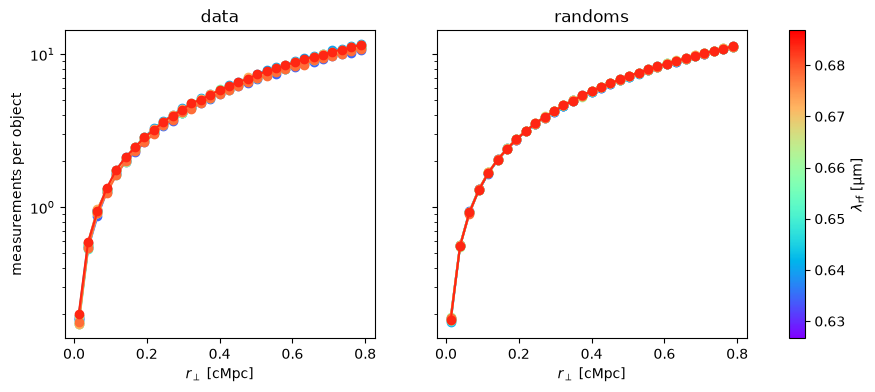

In [17]:
# mean pixel-measurements per object in each bin (weighted), data vs randoms
cmap = plt.get_cmap('rainbow')
norm = mpl.colors.Normalize(wl_bins.min(), wl_bins.max())

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, idx, title in [(axs[0], iD, 'data'), (axs[1], iR, 'randoms')]:
    mean_C = np.tensordot(w_obj[idx], C3[idx], 1) / w_obj[idx].sum()
    for j in range(n_wl):
        ax.plot(r_c, mean_C[:, j], color=cmap(norm(wl_c[j])), marker='o')
    ax.set_xlabel(r'$r_\perp$ [cMpc]')
    ax.set_yscale('log')
    ax.set_title(title)
axs[0].set_ylabel('measurements per object')
fig.colorbar(mpl.cm.ScalarMappable(norm, cmap), ax=axs, label=r'$\lambda_{\rm rf}$ [µm]')
plt.show()